# EN3160 — Image Processing and Machine Vision
## Assignment 02 - Fitting and Alignment

Name: K. D. Manatunga.
Index number: 230395T
GitHub repository: https://github.com/KaveeDiv23/Computer-Vision-Assignment-02

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter
from scipy.optimize import least_squares

def load_rgb(filename, flag=cv.IMREAD_COLOR):
    im = cv.imread(f"a2images/{filename}", flag)
    if im is None: raise FileNotFoundError(filename)
    return cv.cvtColor(im, cv.COLOR_BGR2RGB)

#### Question 1

In [2]:
im = load_rgb("the_berry_farms_sunflower_field.jpeg", cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(im, cv.COLOR_RGB2GRAY).astype(np.float32) / 255
h, w = gray.shape

sigmas = np.geomspace(1.5, 17, 24)
response = np.stack([s**2 * gaussian_laplace(gray, float(s)) for s in sigmas])
peaks = np.argwhere((response == maximum_filter(response, size=(3,11,11))) &
                    (response > 0.18))

print(f"Image: {w} × {h}")
print(f"Sigma range: {sigmas[0]:.1f} - {sigmas[-1]:.1f}")
print("Candidate extrema:", len(peaks))

Image: 360 × 360
Sigma range: 1.5 - 17.0
Candidate extrema: 179


In [3]:
hsv = cv.cvtColor(im,cv.COLOR_RGB2HSV)
yellow = cv.inRange(hsv,(12,95,65),(42,255,255)) > 0
flowers = []

for k,y,x in peaks:
    s = sigmas[k]; r = np.sqrt(2)*s; m = int(np.ceil(1.85*r))
    if y < 0.54*h or r < 2.4 or min(x-m,y-m) < 0 or x+m >= w or y+m >= h: continue

    yy,xx = np.ogrid[-m:m+1,-m:m+1]
    dist2 = xx**2+yy**2
    core = dist2 <= (0.65*r)**2
    ring = (dist2 >= (1.1*r)**2) & (dist2 <= (1.85*r)**2)
    patch = yellow[y-m:y+m+1,x-m:x+m+1]
    center_gray = gray[y-m:y+m+1,x-m:x+m+1][core].mean()

    if patch[ring].mean() < 0.75 or patch[core].mean() > 0.25 or center_gray >= 0.20: continue

    angles = np.arctan2(yy,xx)+np.pi
    coverage = sum(patch[ring & (angles>=j*np.pi/6) &
                   (angles<(j+1)*np.pi/6)].mean() >= 0.55 for j in range(12))
    if coverage < 10: continue

    flowers.append((int(x),int(y),float(s),float(r),float(response[k,y,x])))

flowers.sort(key=lambda f:-f[3])
print("Detected sunflower centers:",len(flowers))
for i,(x,y,s,r,score) in enumerate(flowers[:5],1):
    print(f"{i}. Center=({x},{y}), σ={s:.2f}, radius={r:.2f}")

Detected sunflower centers: 38
1. Center=(282,338), σ=7.31, radius=10.33
2. Center=(106,255), σ=5.92, radius=8.37
3. Center=(179,327), σ=5.92, radius=8.37
4. Center=(178,261), σ=5.32, radius=7.53
5. Center=(274,258), σ=4.79, radius=6.77


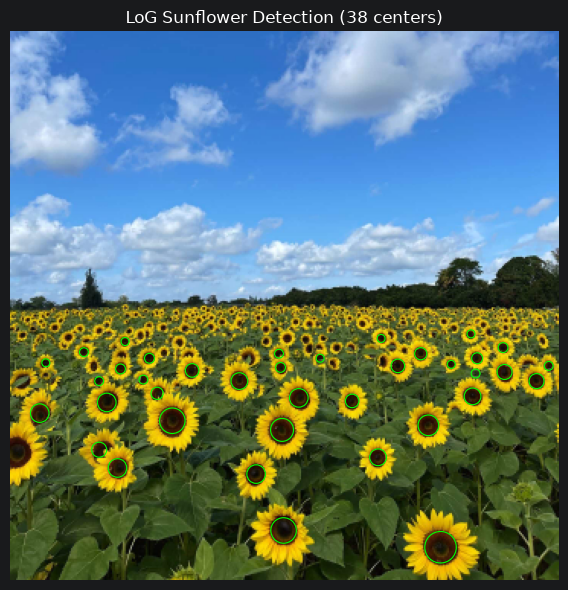

In [4]:
fig, ax = plt.subplots(figsize=(7,6))
ax.imshow(im)
for x,y,s,r,score in flowers:
    ax.add_patch(plt.Circle((x,y), r, fill=False, color="lime", lw=0.8))
ax.set_title(f"LoG Sunflower Detection ({len(flowers)} centers)")
ax.axis("off"); plt.tight_layout(); plt.show()

**Interpretation**

Scale-normalized LoG filtering was performed over 24 scales (σ = 1.5–17.0 px), followed by scale-space extrema detection. Additional filtering based on center darkness, yellow-petal distribution, and angular coverage was applied to reduce false positives.

The improved method retained 38 candidate sunflower centers. The largest detected circle had center (282, 338) and radius 10.33 px in the reduced image.

The method successfully identified several prominent sunflower disks while rejecting some incorrect detections. However, overlapping flowers, weak contrast, and variations in illumination may still produce missed or false detections. The estimated circles approximate the dark central disks rather than the entire sunflower heads.

#### Question 02

##### 2 (a)

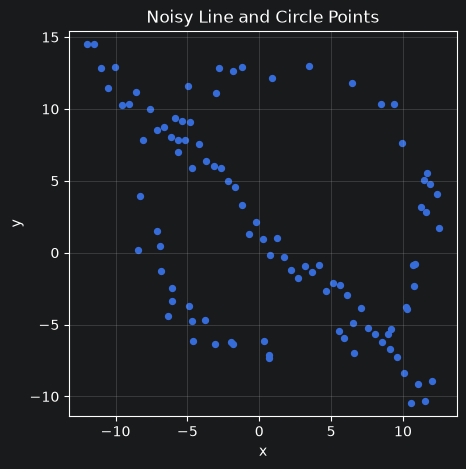

In [5]:
rng = np.random.default_rng(0)
n = 50; r_gt = 10; c_gt = np.array([2.,3.])

t = rng.uniform(0, 2*np.pi, n)
noise = (r_gt/16) * rng.standard_normal(n)
X_circ = np.column_stack((c_gt[0]+(r_gt+noise)*np.cos(t),
                          c_gt[1]+(r_gt+noise)*np.sin(t)))

x = np.linspace(-12,12,n)
X_line = np.column_stack((x, -x+2+rng.standard_normal(n)))
X = np.vstack((X_circ,X_line))

plt.figure(figsize=(5,5))
plt.scatter(X[:,0],X[:,1],s=18)
plt.title("Noisy Line and Circle Points")
plt.xlabel("x"); plt.ylabel("y")
plt.axis("equal"); plt.grid(alpha=0.3); plt.show()

In [6]:
def line_model(p,q):
    v = q-p; L = np.linalg.norm(v)
    if L < 1e-9: return None
    u = np.array([-v[1],v[0]])/L
    return u, float(u@p)

def line_error(X,model):
    u,d = model
    return np.abs(X@u-d)

def fit_tls(X):
    c = X.mean(axis=0)
    u = np.linalg.svd(X-c)[2][-1]
    return u, float(u@c)

def ransac_line(X,seed=10,threshold=0.85,n_iter=1500):
    rg = np.random.default_rng(seed); best = None
    for _ in range(n_iter):
        idx = rg.choice(len(X),2,replace=False)
        model = line_model(*X[idx])
        if model is None: continue
        e = line_error(X,model); mask = e < threshold
        score = (mask.sum(),-np.median(e[mask]) if mask.any() else -np.inf)
        if best is None or score > best[0]:
            best = (score,idx,model,mask)
    _,idx,hyp,mask = best
    if mask.sum() < 30: raise RuntimeError("Insufficient line consensus")
    for _ in range(3):
        model = fit_tls(X[mask])
        new = line_error(X,model) < threshold
        if np.array_equal(mask,new): break
        mask = new
    return {"sample":idx,"initial":hyp,"model":fit_tls(X[mask]),"mask":mask}

In [7]:
line = ransac_line(X)
u,d = line["model"]
rem = X[~line["mask"]]

print("Line inliers:",line["mask"].sum())
print(f"Line: {u[0]:.4f}x + {u[1]:.4f}y = {d:.4f}")
print("Unit-normal length:",np.linalg.norm(u))
print("Remaining points:",len(rem))

Line inliers: 44
Line: 0.7049x + 0.7093y = 1.7045
Unit-normal length: 1.0
Remaining points: 56


##### 2 (b)

In [8]:
def circle_model(pts):
    p,q,r = pts
    A = 2*np.vstack((q-p,r-p))
    if abs(np.linalg.det(A)) < 1e-5: return None
    b = np.array([q@q-p@p,r@r-p@p])
    c = np.linalg.solve(A,b); R = np.linalg.norm(p-c)
    if not np.isfinite(R) or not 1 < R < 40: return None
    return (*c,R)

def circle_error(X,c):
    return np.abs(np.linalg.norm(X-np.array(c[:2]),axis=1)-c[2])

def ransac_circle(X,seed=11,threshold=0.85,n_iter=2500):
    rg = np.random.default_rng(seed); best = None
    for _ in range(n_iter):
        idx = rg.choice(len(X),3,replace=False)
        model = circle_model(X[idx])
        if model is None: continue
        e = circle_error(X,model); mask = e < threshold
        score = (mask.sum(),-np.median(e[mask]) if mask.any() else -np.inf)
        if best is None or score > best[0]:
            best = (score,idx,model,mask)
    _,idx,hyp,mask = best
    if mask.sum() < 30: raise RuntimeError("Insufficient circle consensus")
    for _ in range(3):
        fit = least_squares(
            lambda m: np.linalg.norm(X[mask]-m[:2],axis=1)-m[2],
            hyp,bounds=([-np.inf,-np.inf,0.01],[np.inf,np.inf,50])
        ).x
        new = circle_error(X,fit) < threshold
        if np.array_equal(mask,new): break
        mask = new
    fit = least_squares(
        lambda m: np.linalg.norm(X[mask]-m[:2],axis=1)-m[2],
        fit,bounds=([-np.inf,-np.inf,0.01],[np.inf,np.inf,50])
    ).x
    return {"sample":idx,"initial":hyp,"model":fit,"mask":mask}

In [9]:
circ = ransac_circle(rem)
cx,cy,r = circ["model"]

print("Circle inliers:",circ["mask"].sum())
print(f"Center: ({cx:.4f}, {cy:.4f})")
print(f"Radius: {r:.4f}")

Circle inliers: 40
Center: (2.1500, 2.7357)
Radius: 9.9402


##### 2 (c)

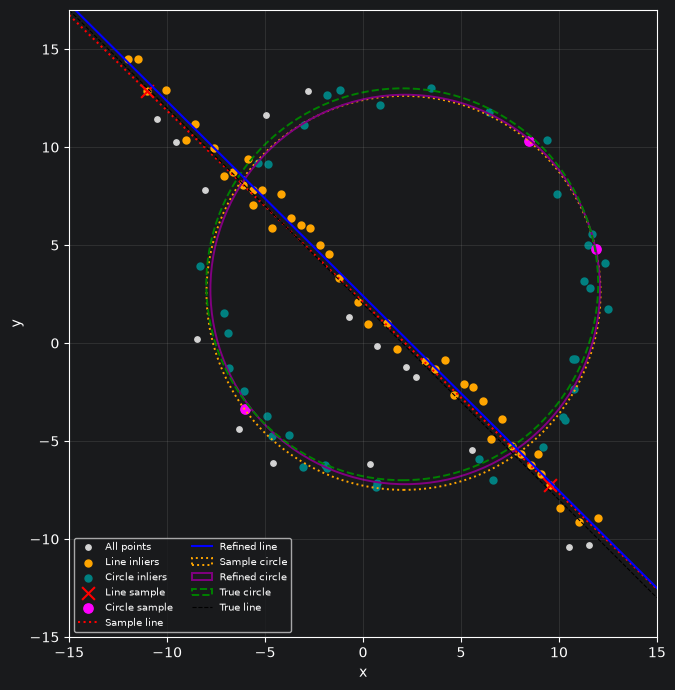

In [10]:
fig,ax = plt.subplots(figsize=(7,7))
ax.scatter(X[:,0],X[:,1],s=15,c="lightgray",label="All points")
ax.scatter(X[line["mask"],0],X[line["mask"],1],s=25,c="orange",label="Line inliers")
ax.scatter(rem[circ["mask"],0],rem[circ["mask"],1],s=25,c="teal",label="Circle inliers")
ax.scatter(*X[line["sample"]].T,s=85,c="red",marker="x",label="Line sample")
ax.scatter(*rem[circ["sample"]].T,s=45,c="magenta",label="Circle sample")

xx = np.linspace(-15,15,300)
for model,style,label in [(line["initial"],"r:","Sample line"),
                           (line["model"],"b-","Refined line")]:
    u,d = model
    if abs(u[1]) > 1e-8:
        ax.plot(xx,(d-u[0]*xx)/u[1],style,label=label)
    else:
        ax.axvline(d/u[0],color="blue",label=label)

for model,color,style,label in [(circ["initial"],"orange",":","Sample circle"),
                                 (circ["model"],"purple","-","Refined circle"),
                                 ((2,3,10),"green","--","True circle")]:
    ax.add_patch(plt.Circle(model[:2],model[2],fill=False,
                             color=color,ls=style,lw=1.4,label=label))

ax.plot(xx,-xx+2,"k--",lw=0.8,label="True line")
ax.set(xlim=(-15,15),ylim=(-15,17),xlabel="x",ylabel="y")
ax.set_aspect("equal"); ax.grid(alpha=0.2)
ax.legend(fontsize=7,ncol=2); plt.tight_layout(); plt.show()

##### 2 (d)

In [11]:
first = ransac_circle(X,seed=12)
fc = first["model"]

print("Circle-first")
print("Inliers:",first["mask"].sum())
print(f"Center: ({fc[0]:.4f}, {fc[1]:.4f}), Radius: {fc[2]:.4f}")
print("Line-first")
print(f"Inliers: {circ['mask'].sum()}, Center: ({cx:.4f}, {cy:.4f}), Radius: {r:.4f}")

Circle-first
Inliers: 47
Center: (2.1476, 2.7848), Radius: 9.9371
Line-first
Inliers: 40, Center: (2.1500, 2.7357), Radius: 9.9402


**Interpretation**

Custom RANSAC was used to estimate the line using two-point
samples and perpendicular-distance errors (T = 0.85).
The best consensus contained 44 points, and TLS refinement
produced a unit-normal line approximately equal to
0.7049x + 0.7093y = 1.7045.

After removing the line consensus, circle RANSAC used
three-point samples and radial errors (T = 0.85).
The refined circle had center (2.1500, 2.7357) and
radius 9.9402, close to the actual radius of 10.

Fitting the circle first also produced a reasonable circle,
but included more points generated from the line (6 versus 1).
Thus, fitting order influences consensus contamination and
the separation of intersecting geometric structures.

#### Question 03

##### 3 (a)

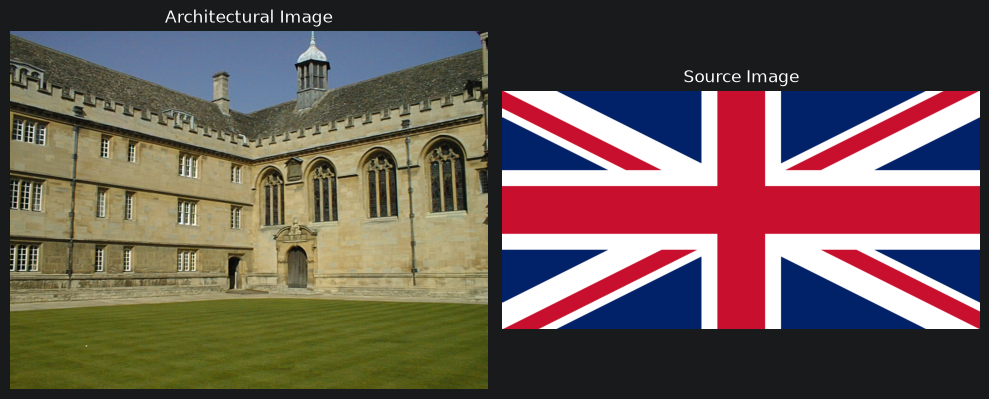

In [12]:
arch1 = load_rgb("wadham.jpg")
flag1 = load_rgb("flag.png")

fig,ax = plt.subplots(1,2,figsize=(10,4))
ax[0].imshow(arch1); ax[0].set_title("Architectural Image")
ax[1].imshow(flag1); ax[1].set_title("Source Image")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

In [13]:
%matplotlib qt

In [14]:
def select_corners(im):
    fig,ax = plt.subplots(figsize=(10,7))
    ax.imshow(im)
    ax.set_title("Select 4 corners: TL → TR → BR → BL")
    plt.show(block=False)
    pts = plt.ginput(4,timeout=0)
    plt.close(fig)

    if len(pts) != 4:
        raise ValueError("Exactly four points are required")
    return np.float32(pts)

In [15]:
quad1 = select_corners(arch1)
print("Selected corners:\n",quad1)

Selected corners:
 [[142.60353 202.97012]
 [516.487   288.4618 ]
 [518.7668  461.72485]
 [133.48442 445.76642]]


In [19]:
arch2 = load_rgb("billboard.webp")
flag2 = load_rgb("mountains.jpg")

quad2 = select_corners(arch2)
print("Second image corners:\n",quad2)

Second image corners:
 [[277.59033   90.29355 ]
 [495.60324  105.158066]
 [494.7774   429.7     ]
 [278.41614  442.9129  ]]


In [20]:
# Replace these with your actual clicked coordinates
quad1 = np.float32([
    [142.6033,202.97012],[516.487,288.4618],[518.7668,461.72485],[133.48442,445.76642]
])

quad2 = np.float32([
    [277.59033,90.29355],[495.60324,105.158066],[494.7774,429.7],[278.41614,442.912]
])

In [24]:
%matplotlib inline

In [26]:
def overlay_image(bg,src,quad,alpha=0.85):
    h,w = bg.shape[:2]; sh,sw = src.shape[:2]
    dst = np.asarray(quad,dtype=np.float32)
    corners = np.float32([[0,0],[sw-1,0],[sw-1,sh-1],[0,sh-1]])

    if dst.shape != (4,2) or not cv.isContourConvex(dst.reshape(-1,1,2)):
        raise ValueError("Select four corners of a convex quadrilateral")

    H = cv.getPerspectiveTransform(corners,dst)
    warped = cv.warpPerspective(src,H,(w,h))
    mask = cv.warpPerspective(np.full((sh,sw),255,np.uint8),H,(w,h))/255.
    a = (alpha*mask)[...,None]
    result = np.clip(bg*(1-a)+warped*a,0,255).astype(np.uint8)
    return H,result

Homography 1:
 [[ 3.03636987e-01 -1.39597000e-02  1.42603302e+02]
 [ 1.05318184e-01  2.38312711e-01  2.02970123e+02]
 [ 2.10662453e-04 -3.33444179e-05  1.00000000e+00]]
Homography 2:
 [[2.70516905e-01 2.50488646e-03 2.77590332e+02]
 [2.48662792e-02 2.93124533e-01 9.02935486e+01]
 [8.99848677e-05 6.55569432e-06 1.00000000e+00]]


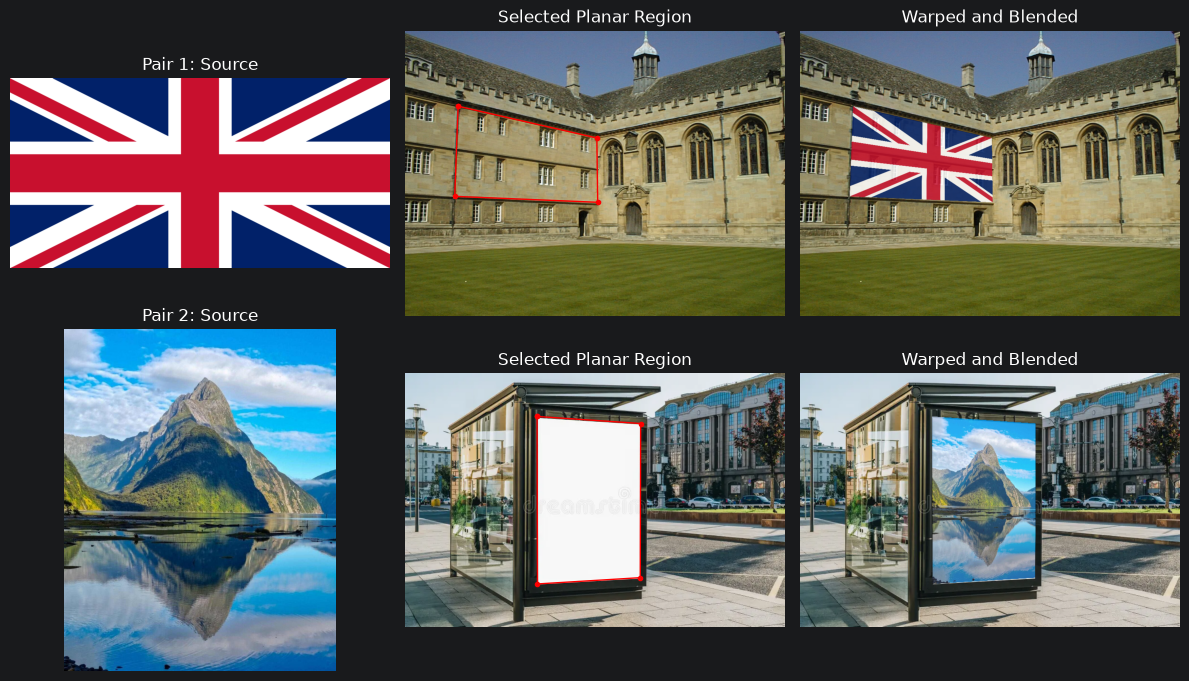

In [27]:
H1,result1 = overlay_image(arch1,flag1,quad1)
print("Homography 1:\n",H1)
H2,result2 = overlay_image(arch2,flag2,quad2)
print("Homography 2:\n",H2)

fig,ax = plt.subplots(2,3,figsize=(12,7))

for i,(bg,src,quad,result) in enumerate([
    (arch1,flag1,quad1,result1),
    (arch2,flag2,quad2,result2)
]):
    pts = np.vstack((quad,quad[0]))
    ax[i,0].imshow(src); ax[i,0].set_title(f"Pair {i+1}: Source")
    ax[i,1].imshow(bg)
    ax[i,1].plot(pts[:,0],pts[:,1],"ro-",lw=1,ms=3)
    ax[i,1].set_title("Selected Planar Region")
    ax[i,2].imshow(result); ax[i,2].set_title("Warped and Blended")

for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.show()

**Interpretation**

Two image pairs were used to demonstrate planar homography and perspective image blending. Four corner points were selected interactively on each destination image, and the corresponding homography matrices were estimated using `cv.getPerspectiveTransform()`. The source images were then perspective-warped and blended onto the selected surfaces using an alpha value of 0.85.

The transformed images follow the perspective of the selected quadrilateral regions, demonstrating projective mapping between planar surfaces. However, the realism of the results depends on the accuracy of the selected corners, the planarity of the surfaces, and differences in lighting and texture. Incorrect corner selection or non-planar surfaces can introduce visible distortion.

**Image selection:** The first pair was selected to demonstrate image placement on an architectural surface. The second pair was selected to demonstrate the same transformation on a different planar region.

